<h1 style="font-family:verdana;"> <center> </center> </h1>
<h1 style="font-family:verdana;"> <center>Basic Introduction To Machine Learning</center> </h1>
<h1 style="font-family:verdana;"> <center>AL-2002 Artifical Intelligence Spring 2026</center> </h1>
<p><center style="color:#159364; font-family:cursive; font-size:20px;">Instructor: Ms. Zill-E-Huma</center></p>

***

Name: Mohammad Rohaan

Reg No.: 22I-2327

Sec: Sec-F
***


# Exploratory Data Analysis and Pre-processing on Black Friday Sales
A retail company `“ABC Private Limited”` wants to understand the customer purchase behaviour (specifically, purchase amount) against various products of different categories. They have shared purchase summary of various customers for selected high volume products from last month.
The data set also contains customer demographics (age, gender, marital status, citytype, stayincurrentcity), product details (productid and product category) and Total purchaseamount from last month.

Now, they want to build a model to predict the purchase amount of customer against various products which will help them to create personalized offer for customers against different products.
## **Tasks to perform**
**`Purchase column`** is the **`Target Variable`**, perform Univariate Analysis and Bivariate Analysis w.r.t the Purchase.

Masked in the column description means already converted from categorical value to numerical column.


### **DATA PREPROCESSING**

* Check basic statistics of dataset e.g. mean, median, std, 1st quartile, 2nd quartile, and 3rd quartiles.
* Check for missing values (NaN and NULL values) in the data
* Check for unique values in data

### **Perform EDA**
* Purchase Distribution (find the correlation between the features, identifying which feautre contribute the most.)
* Check for outliers
* Analysis by Gender, Marital Status, occupation, occupation vs purchase , purchase by city, purchase by age group, etc
* Drop unnecessary fields
* Convert categorical data into integer using map function (e.g 'Gender' column), e.g.,
* missing value treatment.
* Rename columns
* fill nan values
* map range variables into integers (e.g 'Age' column)

### **Data Visualisation**
* visualize individul column
  * Age vs Purchased
  * Occupation vs Purchased
  * Product_category_1 vs Purchased
  * Product_category_2 vs Purchased
  * Product_category_3 vs Purchased
  * City category pie chart

check for more possible plots

# Importing Necessary Libraries

In [2]:
import numpy as np # For Numerical Operations Like arrays, etc
import pandas as pd # For Data Manipulation and Analysis
import matplotlib.pyplot as plt # For Data Visualization
import seaborn as sns # For Advanced Visualization

# 📥 Load The Dataset

In [7]:
# Load The DataSet
df = pd.read_csv('train.csv')

Display (Look into) the first 5 entries and last 5 entries of dataset.

In [8]:
# Display The First 5 Rows
print(df.head())

   User_ID Product_ID Gender   Age  Occupation City_Category  \
0  1000001  P00069042      F  0-17          10             A   
1  1000001  P00248942      F  0-17          10             A   
2  1000001  P00087842      F  0-17          10             A   
3  1000001  P00085442      F  0-17          10             A   
4  1000002  P00285442      M   55+          16             C   

  Stay_In_Current_City_Years  Marital_Status  Product_Category_1  \
0                          2               0                   3   
1                          2               0                   1   
2                          2               0                  12   
3                          2               0                  12   
4                         4+               0                   8   

   Product_Category_2  Product_Category_3  Purchase  
0                 NaN                 NaN      8370  
1                 6.0                14.0     15200  
2                 NaN                 NaN   

Find the dimensionality of dataset

In [9]:
# Display The Dimension (Rows,Cols) Of The DataSet
print("Dimensionality of dataset",df.shape)

Dimensionality of dataset (550068, 12)


Show the summary of dataset.

Statistical summary of numerical variables

In [10]:
# Get a Statistical summary of numerical variables
print(df.describe())

            User_ID     Occupation  Marital_Status  Product_Category_1  \
count  5.500680e+05  550068.000000   550068.000000       550068.000000   
mean   1.003029e+06       8.076707        0.409653            5.404270   
std    1.727592e+03       6.522660        0.491770            3.936211   
min    1.000001e+06       0.000000        0.000000            1.000000   
25%    1.001516e+06       2.000000        0.000000            1.000000   
50%    1.003077e+06       7.000000        0.000000            5.000000   
75%    1.004478e+06      14.000000        1.000000            8.000000   
max    1.006040e+06      20.000000        1.000000           20.000000   

       Product_Category_2  Product_Category_3       Purchase  
count       376430.000000       166821.000000  550068.000000  
mean             9.842329           12.668243    9263.968713  
std              5.086590            4.125338    5023.065394  
min              2.000000            3.000000      12.000000  
25%              5

Identify the null Value and NAN values (missing values) from the dataset, and remove it or fill it decide it based upon your conclusion.

In [26]:
# Checking For Missing values (NAN/NULL) as isnull() Returns True (1) If Found Null/NAN/None
missing_values=df.isnull().sum()
print("TOTAL MISSING VALUES PER COLUMN = ",missing_values)

# Filling Missing Values For Categorical Columns
df['Product_Category_2']=df['Product_Category_2'].fillna(df['Product_Category_2'].median())
df['Product_Category_3']=df['Product_Category_3'].fillna(df['Product_Category_3'].median())

# Display The First 5 Rows
print(df.head())


TOTAL MISSING VALUES PER COLUMN =  User_ID                       0
Product_ID                    0
Gender                        0
Age                           0
Occupation                    0
City_Category                 0
Stay_In_Current_City_Years    0
Marital_Status                0
Product_Category_1            0
Product_Category_2            0
Product_Category_3            0
Purchase                      0
Purchase_Binned               0
dtype: int64
   User_ID Product_ID  Gender   Age  Occupation  City_Category  \
0  1000001  P00069042       0  0-17          10              0   
1  1000001  P00248942       0  0-17          10              0   
2  1000001  P00087842       0  0-17          10              0   
3  1000001  P00085442       0  0-17          10              0   
4  1000002  P00285442       1   55+          16              2   

   Stay_In_Current_City_Years  Marital_Status  Product_Category_1  \
0                           2               0                   3   
1

Check the duplicate values

In [15]:
# Check The Duplicate Values as duplicated() Returns True (1) If Found Duplicate Value
print("Duplicate Values = ",df.duplicated().sum())

Duplicate Values =  0


Count the Purchase distribution. If data is imbalanced, your model may become biased. So resolve it if data is biased.

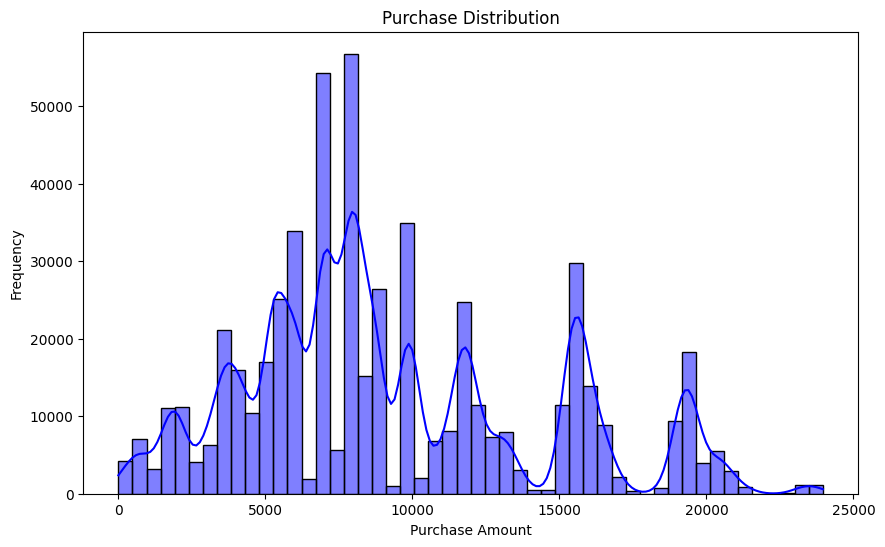

count    550068.000000
mean       9263.968713
std        5023.065394
min          12.000000
25%        5823.000000
50%        8047.000000
75%       12054.000000
max       23961.000000
Name: Purchase, dtype: float64


/tmp/ipykernel_17347/3553634785.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Purchase_Binned', data=df, palette='Blues')  # Count the frequency of each purchase category


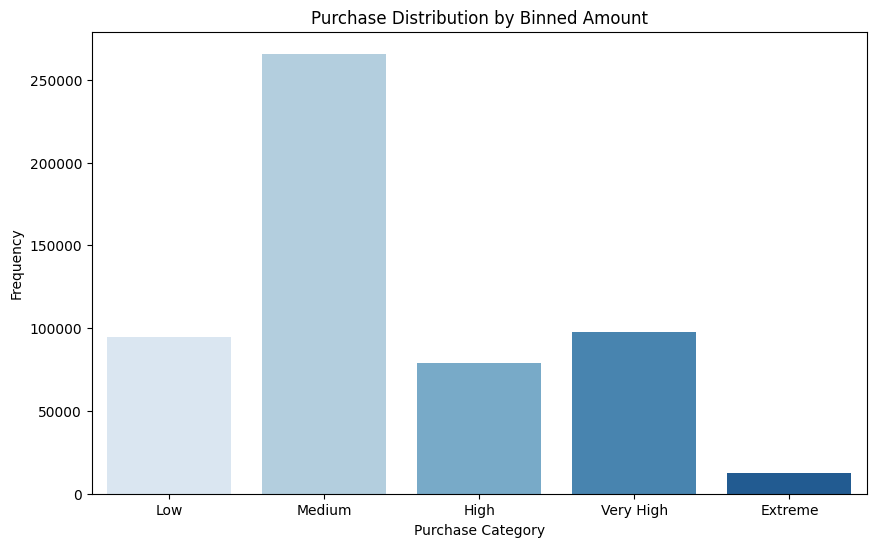

Purchase_Binned
Medium       265695
Very High     97832
Low           94923
High          78927
Extreme       12691
Name: count, dtype: int64
Resampled Purchase distribution:
Purchase_Binned
Low          265695
Medium       265695
High         265695
Very High    265695
Extreme      265695
Name: count, dtype: int64


In [28]:
# Visualizing the distribution of the 'Purchase' column
plt.figure(figsize=(10,6))
# bins=50: This divides the purchase data into 50 intervals, creating 50 bins in the histogram.
# kde=True: Adds the KDE curve to the histogram, showing a smooth estimate of the data distribution.
sns.histplot(df['Purchase'], bins=50, kde=True, color='blue')
plt.title('Purchase Distribution')
plt.xlabel('Purchase Amount')
plt.ylabel('Frequency')
plt.show()

# Check the summary statistics of the 'Purchase' column
print(df['Purchase'].describe())

# ---------------  HISTOGRAM -------------- #

# Create bins for Purchase amounts (e.g., Low, Medium, High, etc.)
# The 'bins' define the ranges of purchase amounts, and the 'labels' are the categories assigned to each range.
bins = [0, 5000, 10000, 15000, 20000, 25000]  # Purchase amount ranges (Low, Medium, High, Very High, Extreme)
labels = ['Low', 'Medium', 'High', 'Very High', 'Extreme']  # Categories for each range

# Using the pd.cut() function to create the 'Purchase_Binned' column which assigns each purchase to a category
# 'Purchase' is the original purchase amount column, and 'bins' are the defined ranges with corresponding 'labels'.
df['Purchase_Binned'] = pd.cut(df['Purchase'], bins=bins, labels=labels)

# Visualize the distribution of the binned purchase amounts
# Create a bar plot with count of entries in each purchase category
plt.figure(figsize=(10,6))  # Set figure size for the plot
sns.countplot(x='Purchase_Binned', data=df, palette='Blues')  # Count the frequency of each purchase category
plt.title('Purchase Distribution by Binned Amount')  # Set title of the plot
plt.xlabel('Purchase Category')  # Label for the x-axis
plt.ylabel('Frequency')  # Label for the y-axis
plt.show()  # Display the plot

# Check the frequency of each bin in the 'Purchase_Binned' column
# This will give the number of entries in each purchase category
print(df['Purchase_Binned'].value_counts())  # Display the frequency of each purchase category

"""
Handling Imbalance ---> To handle this imbalance, there are two common techniques:

Oversampling the minority class: This involves increasing the number of samples
in the minority class by creating synthetic data points (using techniques like SMOTE).

Undersampling the majority class: This involves reducing the number of samples
in the majority class, which is typically not preferred unless you have a large
dataset, as it can lead to losing valuable information.
"""

"""
Before applying SMOTE, We need to encode categorical columns into numeric format.
You can achieve this by using techniques like Label Encoding or One-Hot Encoding.
First Encode Categorical Columns
For simplicity, let's use Label Encoding (which is suitable for categorical
columns with a natural order, like Gender, Marital_Status, etc.).
"""

# Step 1: Map the 'Age' column to numerical values
age_mapping = {'0-17': 0, '18-25': 1, '26-35': 2, '36-45': 3, '46-50': 4, '51-55': 5, '55+': 6}
df['Age'] = df['Age'].map(age_mapping)

# Step 2: Map the 'Gender' column to 0 and 1 (assuming 0 = Male, 1 = Female)
df['Gender'] = df['Gender'].map({0: 0, 1: 1})

# Step 3: Check for any other categorical columns and map them to numeric values (e.g., 'City_Category')
df['City_Category'] = df['City_Category'].map({0: 0, 1: 1, 2: 2})

# Step 4: Now, drop 'Product_ID' and 'Purchase_Binned' as they are not needed for numerical modeling
X = df.drop(columns=['Purchase', 'Purchase_Binned', 'Product_ID'])  # Features
y = df['Purchase_Binned']  # Target variable

# Step 5: Initialize SMOTE object
smote = SMOTE(sampling_strategy='auto', random_state=42)  # Create SMOTE object to automatically balance the dataset

# Step 6: Apply SMOTE to the data
X_resampled, y_resampled = smote.fit_resample(X, y)  # Apply SMOTE to create synthetic data for minority classes

# Step 7: Check the distribution of the resampled data
print("Resampled Purchase distribution:")
print(y_resampled.value_counts())  # Check how balanced the categories are now


Check for unique values in data `(target variable)`

In [29]:
# Check for unique values in the target variable 'Purchase_Binned'
unique_values_target = df['Purchase_Binned'].unique()

# Print the unique values
print("Unique values in the target variable (Purchase_Binned):")
print(unique_values_target)

# Also, check the count of each unique value
print("\nCounts of each unique value in the target variable:")
print(df['Purchase_Binned'].value_counts())

Unique values in the target variable (Purchase_Binned):
['Medium', 'Very High', 'Low', 'High', 'Extreme']
Categories (5, object): ['Low' < 'Medium' < 'High' < 'Very High' < 'Extreme']

Counts of each unique value in the target variable:
Purchase_Binned
Medium       265695
Very High     97832
Low           94923
High          78927
Extreme       12691
Name: count, dtype: int64


*Convert* categorical data into integer using map function (e.g 'Gender' column)

In [30]:
# Convert 'Gender' to numeric (assuming 0 = Male, 1 = Female)
df['Gender'] = df['Gender'].map({0: 0, 1: 1})

# Convert 'Age' to numeric values (already done, but showing for clarity)
age_mapping = {'0-17': 0, '18-25': 1, '26-35': 2, '36-45': 3, '46-50': 4, '51-55': 5, '55+': 6}
df['Age'] = df['Age'].map(age_mapping)

# Convert 'City_Category' to numeric (assuming 0 = Type 1, 1 = Type 2, 2 = Type 3)
df['City_Category'] = df['City_Category'].map({0: 0, 1: 1, 2: 2})

# Convert 'Marital_Status' to numeric (assuming 0 = Single, 1 = Married)
df['Marital_Status'] = df['Marital_Status'].map({0: 0, 1: 1})

# Check the converted values
print("Converted Categorical Data:")
print(df[['Gender', 'Age', 'City_Category', 'Marital_Status']].head())

Converted Categorical Data:
   Gender  Age  City_Category  Marital_Status
0       0  NaN              0               0
1       0  NaN              0               0
2       0  NaN              0               0
3       0  NaN              0               0
4       1  NaN              2               0


### Data Visualisation

Graph (histogram, scatter plot, bar blot, box plot, heatmap)

Example code for heatmap:


    cols = ["col1", "col2", "col3", "col4", "col5"]

    plt.figure(figsize=(10,6))
    sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm")
    plt.title("Correlation Heatmap (Selected Features)")
    plt.show()

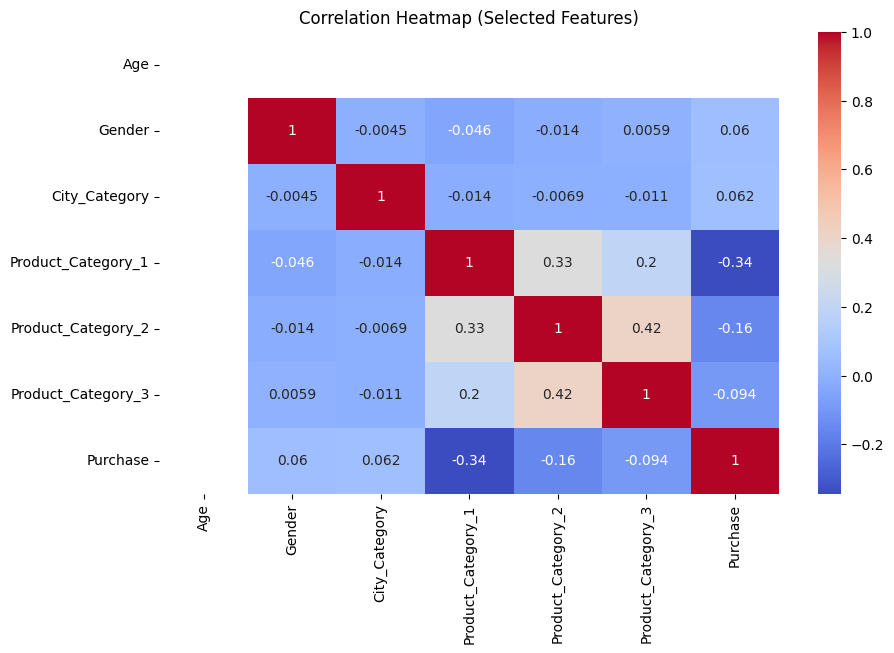

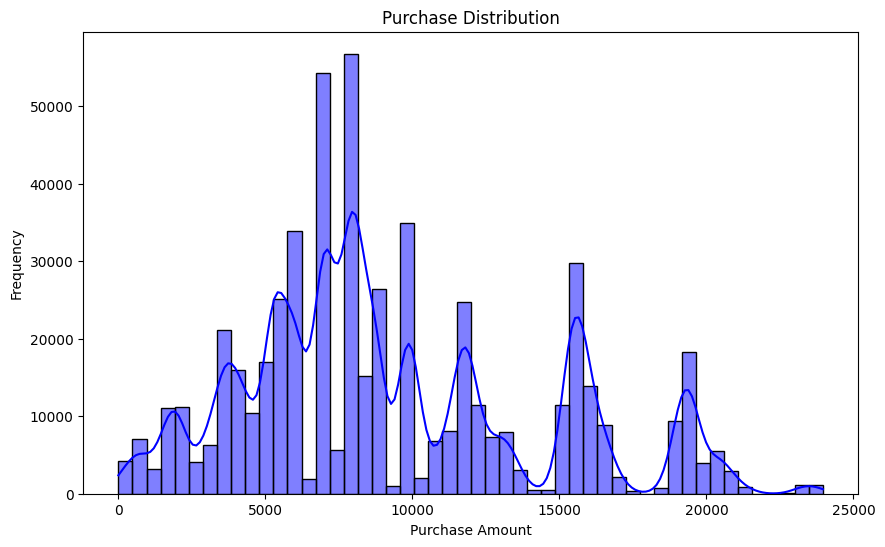

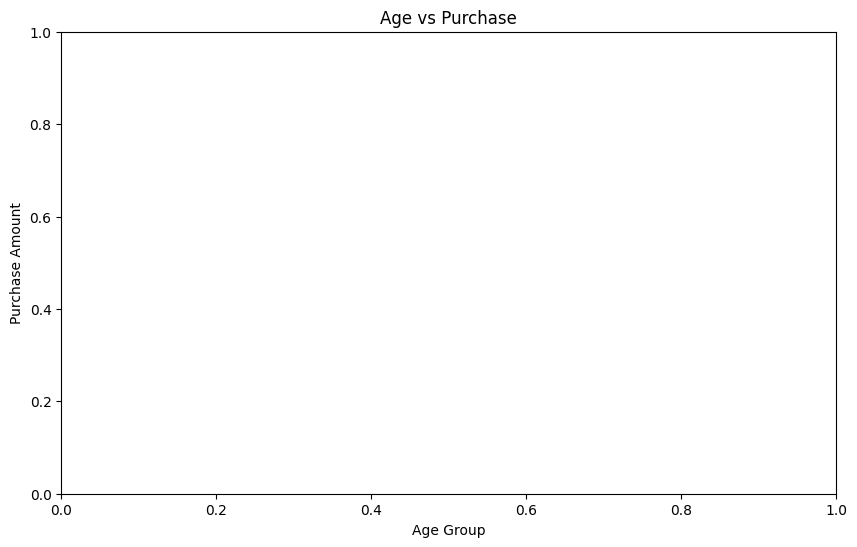

/tmp/ipykernel_17347/591113633.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Gender', y='Purchase', palette='viridis')  # Bar plot with 'Gender' on x-axis and 'Purchase' on y-axis


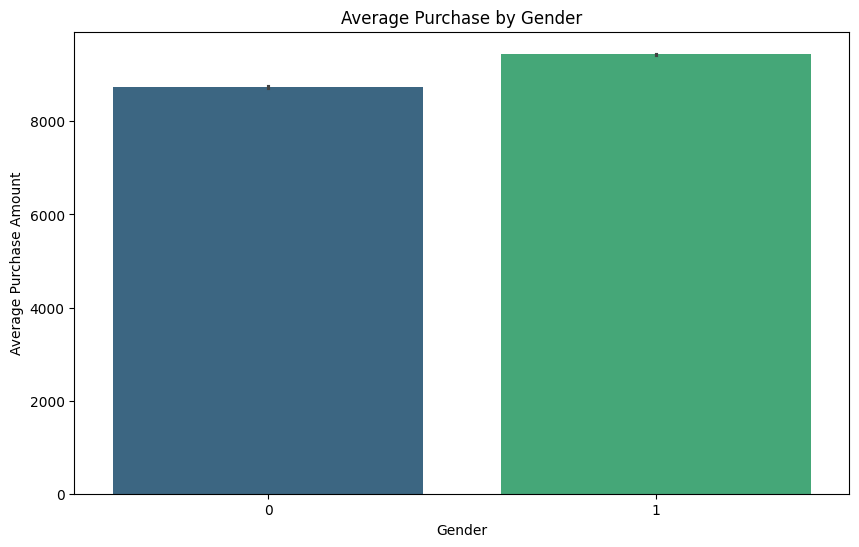

/tmp/ipykernel_17347/591113633.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Marital_Status', y='Purchase', palette='coolwarm')  # Box plot with 'Marital_Status' on x-axis and 'Purchase' on y-axis


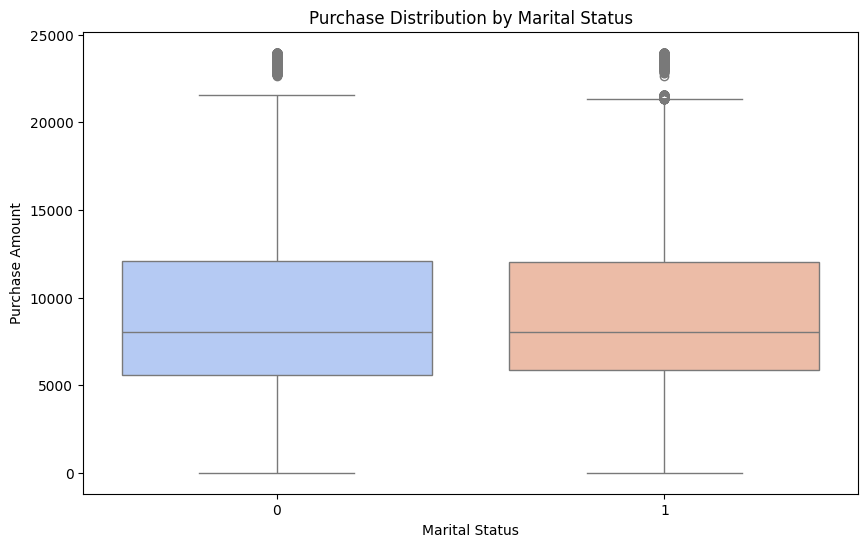

In [33]:
"""
Heatmap (Correlation Matrix)
"""

# List of columns to visualize in the heatmap (you can modify this to include relevant columns)
cols = ["Age", "Gender", "City_Category", "Product_Category_1", "Product_Category_2", "Product_Category_3", "Purchase"]

# Create a figure with specific size for better clarity in visual
plt.figure(figsize=(10,6))

# Create a heatmap using seaborn to visualize correlations between selected columns
# `df[cols].corr()` calculates the correlation matrix for the selected columns
# `annot=True` adds the correlation values on the heatmap
# `cmap="coolwarm"` defines the color palette (cool for negative, warm for positive correlations)
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm")

# Title of the heatmap to describe the plot
plt.title("Correlation Heatmap (Selected Features)")

# Display the plot
plt.show()


"""
Histogram of Purchase Distribution
"""
print()
print()
# Create a histogram for the 'Purchase' column to understand the distribution of purchase amounts
plt.figure(figsize=(10,6))  # Set the size of the plot for better readability
sns.histplot(df['Purchase'], bins=50, kde=True, color='blue')  # 'bins' controls the number of bins, 'kde=True' adds a kernel density estimate line
plt.title('Purchase Distribution')  # Add a title to the histogram
plt.xlabel('Purchase Amount')  # Label the x-axis
plt.ylabel('Frequency')  # Label the y-axis
plt.show()  # Display the plot

"""
Scatter Plot (Age vs Purchase)
"""
print()
print()
# Create a scatter plot to visualize the relationship between 'Age' and 'Purchase' amount
plt.figure(figsize=(10,6))  # Set the figure size
sns.scatterplot(data=df, x='Age', y='Purchase', color='green')  # Scatter plot with 'Age' on x-axis and 'Purchase' on y-axis
plt.title('Age vs Purchase')  # Add a title to the scatter plot
plt.xlabel('Age Group')  # Label for the x-axis
plt.ylabel('Purchase Amount')  # Label for the y-axis
plt.show()  # Display the plot

"""
Bar Plot for Purchase by Gender
"""
print()
print()
# Create a bar plot to compare the average purchase amount by gender
plt.figure(figsize=(10,6))  # Set the figure size
sns.barplot(data=df, x='Gender', y='Purchase', palette='viridis')  # Bar plot with 'Gender' on x-axis and 'Purchase' on y-axis
plt.title('Average Purchase by Gender')  # Add a title
plt.xlabel('Gender')  # Label for x-axis
plt.ylabel('Average Purchase Amount')  # Label for y-axis
plt.show()  # Display the plot

"""
Box Plot for Purchase by Marital Status
"""
print()
print()
# Create a box plot to visualize the distribution of purchases based on marital status
plt.figure(figsize=(10,6))  # Set the figure size
sns.boxplot(data=df, x='Marital_Status', y='Purchase', palette='coolwarm')  # Box plot with 'Marital_Status' on x-axis and 'Purchase' on y-axis
plt.title('Purchase Distribution by Marital Status')  # Add a title to the box plot
plt.xlabel('Marital Status')  # Label for x-axis
plt.ylabel('Purchase Amount')  # Label for y-axis
plt.show()  # Display the plot

Plot the Pie chart for purchase distribution with features.

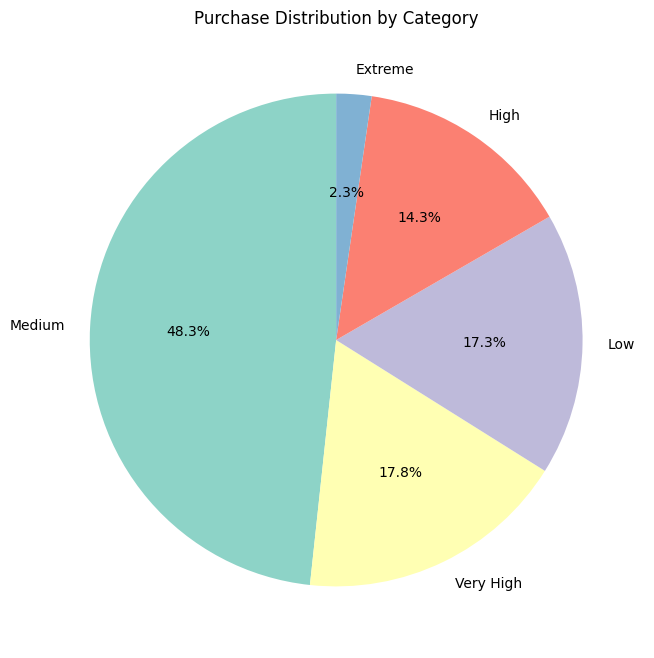

In [34]:
# Plotting a Pie Chart for the 'Purchase_Binned' column
plt.figure(figsize=(8,8))  # Set the figure size to make the pie chart larger

# Create the pie chart
purchase_distribution = df['Purchase_Binned'].value_counts()  # Get the count of each category in 'Purchase_Binned'
plt.pie(purchase_distribution, labels=purchase_distribution.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3", len(purchase_distribution)))

# Set title for the pie chart
plt.title('Purchase Distribution by Category')

# Display the pie chart
plt.show()

Declare feature vector and target variable

In [35]:
# Feature vector (X) - All columns except the target variable 'Purchase' and non-relevant columns like 'Product_ID', 'Purchase_Binned'
X = df.drop(columns=['Purchase', 'Purchase_Binned', 'Product_ID'])

# Target variable (y) - The 'Purchase' column
y = df['Purchase']

# Optionally, print the shapes of X and y to verify the dimensions
print("Feature Vector (X) shape:", X.shape)
print("Target Variable (y) shape:", y.shape)

Feature Vector (X) shape: (550068, 10)
Target Variable (y) shape: (550068,)


Normalize the features through feature scaling

In [36]:
from sklearn.preprocessing import MinMaxScaler  # Import the MinMaxScaler

# Initialize the MinMaxScaler
scaler = MinMaxScaler()

# Fit the scaler on the features and transform the data
X_scaled = scaler.fit_transform(X)

# Convert the scaled features back into a DataFrame for easy readability
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Print the first few rows of the normalized features
print(X_scaled_df.head())

    User_ID  Gender  Age  Occupation  City_Category  \
0  0.000000     0.0  NaN         0.5            0.0   
1  0.000000     0.0  NaN         0.5            0.0   
2  0.000000     0.0  NaN         0.5            0.0   
3  0.000000     0.0  NaN         0.5            0.0   
4  0.000166     1.0  NaN         0.8            1.0   

   Stay_In_Current_City_Years  Marital_Status  Product_Category_1  \
0                         0.5             0.0            0.105263   
1                         0.5             0.0            0.000000   
2                         0.5             0.0            0.578947   
3                         0.5             0.0            0.578947   
4                         1.0             0.0            0.368421   

   Product_Category_2  Product_Category_3  
0              0.4375            0.733333  
1              0.2500            0.733333  
2              0.4375            0.733333  
3              0.7500            0.733333  
4              0.4375            0

/usr/local/lib/python3.12/dist-packages/sklearn/utils/_array_api.py:776: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))
/usr/local/lib/python3.12/dist-packages/sklearn/utils/_array_api.py:793: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmax(X, axis=axis))


If the data is biased then add the biasness.

In [38]:
# Add a column of 1s to the feature matrix X to represent the bias term
# Add a bias column (1s) to the feature matrix X
X_biased = np.c_[np.ones(X_scaled_df.shape[0]), X_scaled_df]

# Check the first few rows to confirm the bias term is added
print("First few rows with Bias Term added:")
print(X_biased[:5])  # Display the first 5 rows

First few rows with Bias Term added:
[[1.00000000e+00 0.00000000e+00 0.00000000e+00            nan
  5.00000000e-01 0.00000000e+00 5.00000000e-01 0.00000000e+00
  1.05263158e-01 4.37500000e-01 7.33333333e-01]
 [1.00000000e+00 0.00000000e+00 0.00000000e+00            nan
  5.00000000e-01 0.00000000e+00 5.00000000e-01 0.00000000e+00
  0.00000000e+00 2.50000000e-01 7.33333333e-01]
 [1.00000000e+00 0.00000000e+00 0.00000000e+00            nan
  5.00000000e-01 0.00000000e+00 5.00000000e-01 0.00000000e+00
  5.78947368e-01 4.37500000e-01 7.33333333e-01]
 [1.00000000e+00 0.00000000e+00 0.00000000e+00            nan
  5.00000000e-01 0.00000000e+00 5.00000000e-01 0.00000000e+00
  5.78947368e-01 7.50000000e-01 7.33333333e-01]
 [1.00000000e+00 1.65590330e-04 1.00000000e+00            nan
  8.00000000e-01 1.00000000e+00 1.00000000e+00 0.00000000e+00
  3.68421053e-01 4.37500000e-01 7.33333333e-01]]


***

                              That's all for today's class, hope you like the class:)